In [4]:
# pip install xgboost
!xgboost
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression

/bin/bash: line 1: xgboost: command not found


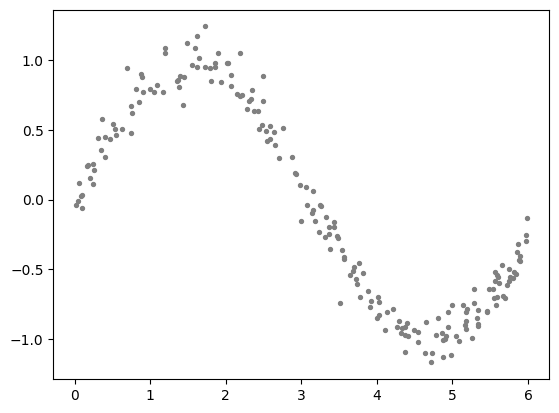

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 0부터 6 사이의 범위에서 무작위로 뽑은 온도 데이터 200개
rand = np.random.default_rng(0)
# 크기 순으로 정렬(np.sort)하여 2차원 형태로 만든다.
x = np.sort(rand.uniform(0, 6, 200)).reshape(-1, 1)
# np.sin() 를 이용해 둥글게 휘어지는 곡선 관계를 만들고, 노이즈를 더해 실제 공정 데이터 같은 정답 데이터 생성
y = np.sin(x).ravel() + rand.normal(0, 0.1, 200)

# 이렇게 만들어진 곡선관계는 직선으로 표현할수가 없다.
plt.scatter(x, y, s=8, c='gray')
plt.show()


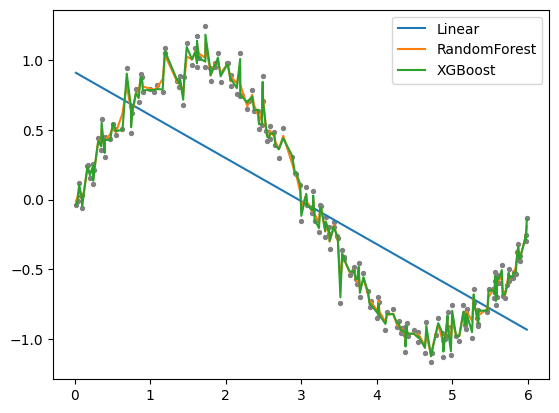

In [9]:
# 각 모델 준비
models = {'Linear': LinearRegression(),
          'RandomForest': RandomForestRegressor(n_estimators=200, random_state=0),
          'XGBoost': XGBRegressor(n_estimators=200, max_depth=3, random_state=0)}

# 모델별로 학습후 결과를 그려본다.
plt.scatter(x, y, s=8, c='gray')
for name, m in models.items():
    m.fit(x, y)
    plt.plot(x, m.predict(x), label=name)
plt.legend(); 
plt.show()

In [ ]:
# 학습 범위(0~6) 밖인 x = 8 예측 : 트리 모델은 마지막 값에 머문다
for name,model in models.items():
    y = model.predict([[8]])
    print(f'{name}:{y[0]:.3f}')

Linear:-1.558
RandomForest:-0.191
XGBoost:-0.145


<h3>Linear:-1.558</h3>
8이라는 학습한적 없는 온도가 들어오자, y = ax + b를 연장하여 -1.558 이라는 터무니없는 낮은 값을 예측
<h3>RandomForest:-0.191 & XGBoost:-0.145</h3>
온도가 8로 아무리 높아져도 더 이상 값을 증가시키지 못하고 마지막 학습 구간의 값인 -0.19 안팎을 예측